# 03. 시황: 밸류체인 전체를 한눈에

**목표:** 01·02가 한 기업을 깊게 본다면, 여기서는 **같은 밸류체인에 있는 기업들의 주가·밸류에이션·뉴스**를 넓게 본다. "시장은 지금 무엇을 믿고 있나"를 숫자로 확인하는 단계다.

- 종목 목록은 플레이북의 `universe`에서 온다 ([playbooks/neocloud.yaml](../playbooks/neocloud.yaml)). 역할별 분류는 스크리닝용 작업 가정이다.
- 수익률은 **현지 통화 기준**, 각 종목의 자국 지수와 비교한다 (일본 Nikkei 225, 한국 KOSPI, 대만 TAIEX, 홍콩 Hang Seng).
- 데이터는 Yahoo Finance. 그날 받은 값을 `data/cache/market/<날짜>/`에 저장해서 같은 날 다시 실행하면 같은 숫자가 나온다.
- **주의:** Yahoo 밸류에이션 값은 기준이 제각각이고 가끔 틀린다. 투자 판단의 입력이 아니라 '어디를 더 볼지' 고르는 용도다.

In [1]:
import sys, json, re
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from research import financials as fin, playbook

pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
plt.rcParams.update({"font.family": ["Malgun Gothic", "AppleGothic", "NanumGothic", "DejaVu Sans"],
                     "axes.unicode_minus": False, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#52514e", "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
                     "ytick.color": "#52514e", "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
                     "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb"})
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"   # 범주 색 고정 순서
from research import market as mk, playbook

PLAYBOOK = "neocloud"
REFRESH = False          # True: 오늘 데이터를 새로 받기
pb = playbook.load(PLAYBOOK)
groups = pb["universe"]
tickers = [t for g in groups.values() for t in g]
names = {t: n for g in groups.values() for t, n in g.items()}
role = {t: r for r, g in groups.items() for t in g}
px = mk.prices(tickers, refresh=REFRESH)
print(f"{len(tickers)}개 종목, 기준일 {px.index[-1].date()}")

15개 종목, 기준일 2026-11-25


## 1. 주가 성과

`1년 지수 대비(%p)`가 음수면 자국 시장보다 못했다는 뜻이다. `52주 고점 대비`는 고점에서 얼마나 내려와 있는지, `연율 변동성`은 주가가 얼마나 크게 흔들리는지를 보여 준다.

In [2]:
perf = mk.performance(px, tickers)
perf.insert(0, "역할", [role[t] for t in perf.index])
perf.insert(0, "기업", [names[t] for t in perf.index])
num = [c for c in perf.columns if c not in ("기업", "역할", "지수", "기준일")]
perf[num] = perf[num].astype(float)
perf.style.format({c: "{:+.1f}" for c in num}, na_rep="-").background_gradient(
    subset=["1년 지수 대비(%p)"], cmap="RdBu", vmin=-60, vmax=60)

,기업,역할,1개월,3개월,6개월,연초 이후,1년,지수,1년 지수 대비(%p),52주 고점 대비(%),연율 변동성(%),기준일
3778.T,SAKURA internet,GPU 클라우드·네오클라우드,-11.0,-27.6,-21.7,-8.7,-16.9,Nikkei 225,-34.0,-41.1,+67.1,2026-11-25
9449.T,GMO Internet Group,GPU 클라우드·네오클라우드,-13.6,-19.5,-4.2,-15.3,-7.3,Nikkei 225,-24.3,-24.6,+46.0,2026-11-25
018260.KS,Samsung SDS,GPU 클라우드·네오클라우드,-9.8,-15.2,-1.1,+12.3,+17.0,KOSPI,-4.8,-46.8,+75.5,2026-11-25
3896.HK,Kingsoft Cloud,GPU 클라우드·네오클라우드,-28.3,-42.3,-56.0,-42.0,-50.2,Hang Seng,-35.9,-66.0,+73.4,2026-11-25
9434.T,SoftBank Corp,통신·인프라 (수요처이자 경쟁자),+0.6,+1.7,+11.8,+15.5,+10.3,Nikkei 225,-6.7,-3.4,+18.1,2026-11-25
9433.T,KDDI,통신·인프라 (수요처이자 경쟁자),-1.7,-1.8,+8.5,+7.1,+8.7,Nikkei 225,-8.3,-8.1,+24.6,2026-11-25
030200.KS,KT,통신·인프라 (수요처이자 경쟁자),+0.8,-11.0,-13.6,-7.5,-2.4,KOSPI,-24.2,-29.4,+34.6,2026-11-25
3774.T,Internet Initiative Japan,통신·인프라 (수요처이자 경쟁자),+12.6,+17.4,+31.1,+44.5,+38.3,Nikkei 225,+21.3,-5.2,+30.2,2026-11-25
9698.HK,GDS Holdings,데이터센터,-40.5,-58.8,-61.0,-61.2,-59.2,Hang Seng,-44.8,-71.6,+60.7,2026-11-25
2382.TW,Quanta Computer,AI 서버 ODM (공급망),-19.6,-21.2,-14.7,-0.7,-1.8,TAIEX,-43.5,-35.2,+41.9,2026-11-25


## 2. 역할별 주가 흐름 (1년 전 = 100)

역할마다 차트 하나, 축 하나. 회색 점선은 해당 그룹 첫 종목의 자국 지수다.

findfont: Font family 'AppleGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'AppleGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'AppleGothic' not found.


findfont: Font family 'NanumGothic' not found.


... (2,866 outputs left out)

findfont: Font family 'AppleGothic' not found.


findfont: Font family 'NanumGothic' not found.


findfont: Font family 'AppleGothic' not found.


findfont: Font family 'NanumGothic' not found.


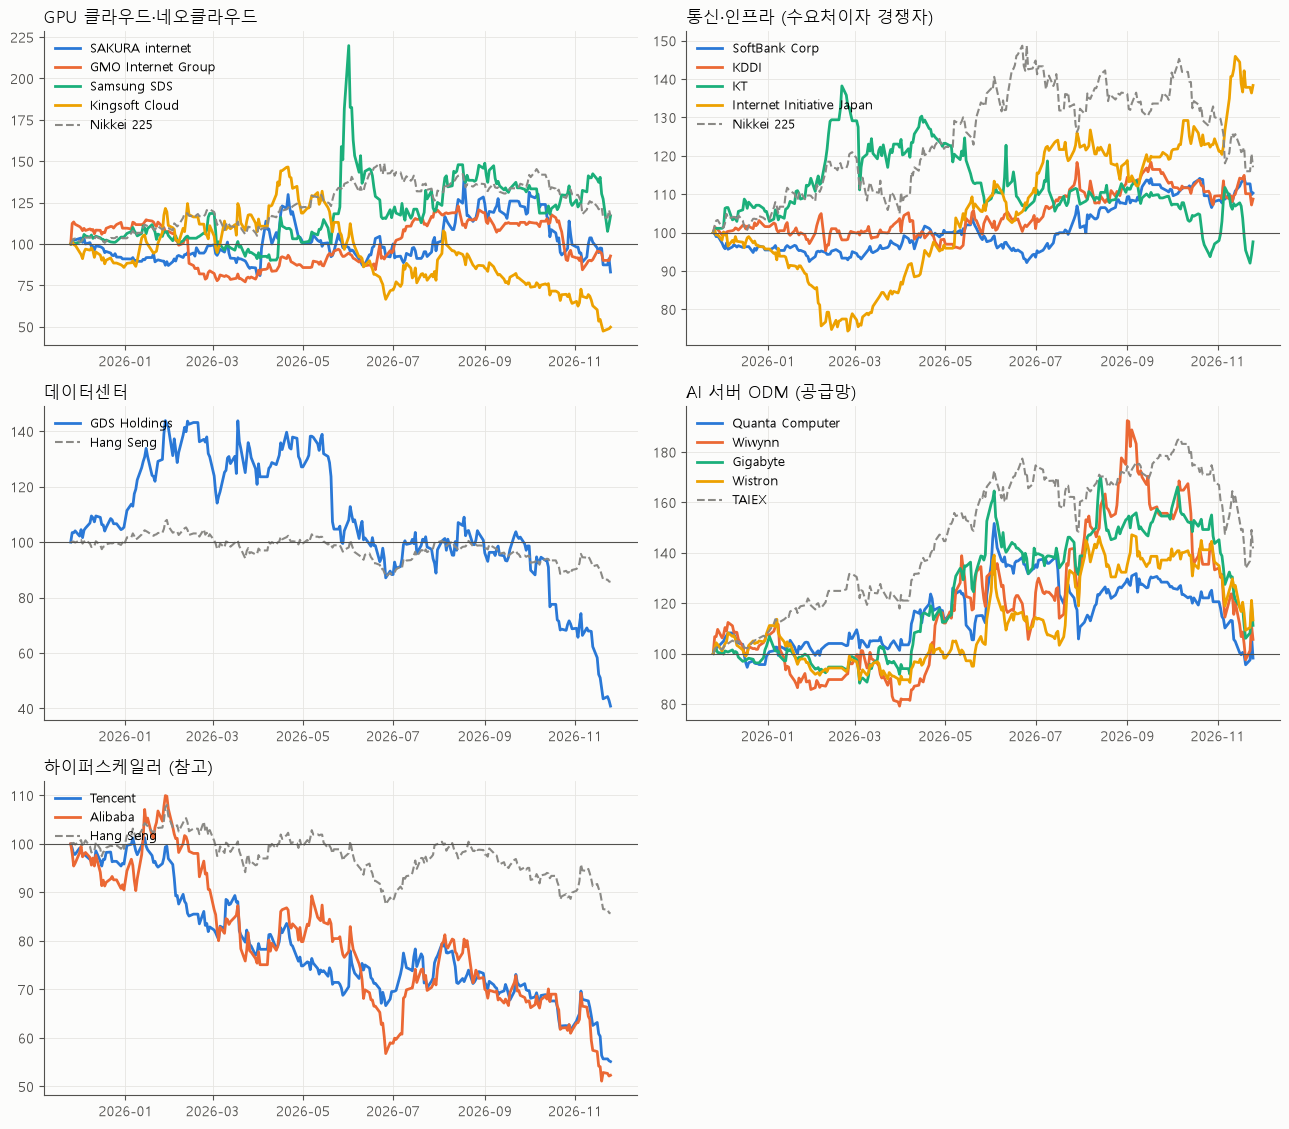

In [3]:
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
rb = mk.rebased(px, list(px.columns), months=12)
n = len(groups); cols = 2; rows = -(-n // cols)
fig, axes = plt.subplots(rows, cols, figsize=(13, 3.8 * rows), squeeze=False)
for a, (g, members) in zip(axes.flat, groups.items()):
    for c, t in zip(COLORS, members):
        a.plot(rb.index, rb[t], color=c, lw=2, label=names[t])
    bm = mk.benchmark_for(list(members)[0])
    if bm and bm[0] in rb:
        a.plot(rb.index, rb[bm[0]], color="#8a8985", lw=1.5, ls="--", label=bm[1])
    a.axhline(100, color="#52514e", lw=0.8)
    a.set_title(g, loc="left"); a.legend(frameon=False, fontsize=9, loc="upper left")
for a in list(axes.flat)[n:]:
    a.set_visible(False)
fig.tight_layout(); plt.show()

## 3. 밸류에이션 스냅샷

시가총액은 현지 통화. 적자 기업은 PER이 비어 있거나 음수다. 🔎 표시는 값이 비정상적으로 커서(PER 100배 초과 또는 음수) **원 자료 확인이 필요한 칸**이다.

In [4]:
val = mk.valuation(tickers, refresh=REFRESH)
val.insert(0, "역할", [role[t] for t in val.index])
val.insert(0, "기업", [names[t] for t in val.index])
val["시가총액(억)"] = val.pop("시가총액") / 1e8
odd = lambda v: "🔎" if pd.notna(v) and (v > 100 or v < 0) else ""
for c in ("PER(지난 12개월)", "PER(예상)"):
    val[c + " 확인"] = val[c].map(odd)
val.style.format({c: "{:,.1f}" for c in val.columns if val[c].dtype.kind == "f"}, na_rep="-")

,기업,역할,통화,PER(지난 12개월),PER(예상),PBR,EV/EBITDA,EV/매출,배당수익률(%),시가총액(억),PER(지난 12개월) 확인,PER(예상) 확인
3778.T,SAKURA internet,GPU 클라우드·네오클라우드,JPY,36.9,34.1,3.2,9.1,3.0,0.2,"1,013.3",,
9449.T,GMO Internet Group,GPU 클라우드·네오클라우드,JPY,15.2,21.3,2.1,5.6,1.6,2.8,"2,938.7",,
018260.KS,Samsung SDS,GPU 클라우드·네오클라우드,KRW,-,16.9,-,6.3,0.6,1.7,"148,976.5",,
3896.HK,Kingsoft Cloud,GPU 클라우드·네오클라우드,HKD,-,-90.0,1.3,6.9,1.9,0.0,143.7,,🔎
9434.T,SoftBank Corp,통신·인프라 (수요처이자 경쟁자),JPY,21.1,20.6,3.7,10.2,2.5,3.7,"114,476.1",,
9433.T,KDDI,통신·인프라 (수요처이자 경쟁자),JPY,15.0,"1,209.0",2.1,8.5,2.4,2.9,"103,825.1",,🔎
030200.KS,KT,통신·인프라 (수요처이자 경쟁자),KRW,-,7.5,-,3.6,0.7,5.3,"110,195.8",,
3774.T,Internet Initiative Japan,통신·인프라 (수요처이자 경쟁자),JPY,28.1,27.5,4.1,9.9,1.7,1.1,"6,989.1",,
9698.HK,GDS Holdings,데이터센터,HKD,6.2,25.6,0.6,10.5,4.7,0.0,209.4,,
2382.TW,Quanta Computer,AI 서버 ODM (공급망),TWD,11.7,8.2,3.1,9.8,0.3,5.5,"10,617.8",,


### 역할별 중앙값

같은 역할 안에서 비교해야 의미가 있다. 서버 제조사와 클라우드 운영사의 PER을 바로 비교하면 안 된다.

In [5]:
cols_ = ["PER(지난 12개월)", "PER(예상)", "PBR", "EV/EBITDA", "EV/매출"]
clean = val[cols_].where((val[cols_] > 0) & (val[cols_] < 100))  # 🔎 값은 빼고
clean.groupby(val["역할"]).median().style.format("{:.1f}", na_rep="-")

,PER(지난 12개월),PER(예상),PBR,EV/EBITDA,EV/매출
역할,,,,,
AI 서버 ODM (공급망),11.1,7.0,2.7,9.2,0.5
GPU 클라우드·네오클라우드,26.0,21.3,2.1,6.6,1.7
데이터센터,6.2,25.6,0.6,10.5,4.7
통신·인프라 (수요처이자 경쟁자),21.1,20.6,3.7,9.2,2.1
하이퍼스케일러 (참고),12.3,9.8,1.6,11.2,2.7


## 4. 최근 헤드라인

Yahoo가 종목에 연결한 기사다. **종목과 직접 관련 없는 기사도 섞여 있다** (예: 업계 일반 기사). 헤드라인은 단서일 뿐이고, 사실 확인은 원문과 공시로 한다.

In [6]:
nw = mk.news(tickers, per_ticker=3, refresh=REFRESH)
nw.insert(1, "기업", nw["ticker"].map(names))
esc = lambda x: str(x or "").replace("|", "/")
lines = ["| 기업 | 날짜 | 헤드라인 | 출처 |", "|---|---|---|---|"]
lines += [f"| {esc(r.기업)} | {esc(r.date)} | [{esc(r.title)}]({r.url}) | {esc(r.publisher)} |" if r.url
          else f"| {esc(r.기업)} | {esc(r.date)} | {esc(r.title)} | {esc(r.publisher)} |" for r in nw.itertuples()]
display(Markdown(chr(10).join(lines)))

| 기업 | 날짜 | 헤드라인 | 출처 |
|---|---|---|---|
| SAKURA internet | 2026-04-25 | [Microsoft Corp. (MSFT) Well-Positioned with Overseas AI Infrastructure and Cybersecurity Investments](https://finance.yahoo.com/sectors/technology/articles/microsoft-corp-msft-well-positioned-034354207.html) | Insider Monkey |
| SAKURA internet | 2026-04-14 | [Microsoft Corporation (MSFT) Affirms $10B AI Infrastructure Expansion in Japan](https://finance.yahoo.com/sectors/technology/articles/microsoft-corporation-msft-affirms-10b-114413330.html) | Insider Monkey |
| SAKURA internet | 2026-04-07 | [Microsoft Unveils $10B Japan AI Investment, Expands Asia Cloud Push](https://finance.yahoo.com/sectors/technology/articles/microsoft-unveils-10b-japan-ai-112647631.html) | GuruFocus.com |
| GMO Internet Group | 2026-11-18 | [Nvidia Beat Puts AI Infrastructure Stocks Back In Focus](https://finance.yahoo.com/technology/ai/articles/nvidia-beat-puts-ai-infrastructure-051357651.html) | Simply Wall St. |
| GMO Internet Group | 2026-10-30 | [3 Cybersecurity Stocks Gaining Attention As Trust In Digital Infrastructure Gets Tested](https://finance.yahoo.com/markets/stocks/articles/3-cybersecurity-stocks-gaining-attention-200853320.html) | Simply Wall St. |
| GMO Internet Group | 2026-10-29 | [GMO Internet Group (TSE:9449) Faces Cyber Attack Fallout, Is It Still A Bargain?](https://finance.yahoo.com/markets/stocks/articles/gmo-internet-group-tse-9449-121811210.html) | Simply Wall St. |
| Samsung SDS | 2026-09-30 | [Samsung Is Pouring Another Billion Into AI Infrastructure. Nvidia And KKR Are Also Backing The Venture.](https://www.ibtimes.com/samsung-pouring-another-billion-ai-infrastructure-nvidia-kkr-are-also-backing-venture-3808016) | International Business Times |
| Samsung SDS | 2026-06-20 | [Anthropic Eyes South Korea Growth Ahead Of IPO With Seoul Office, New Partnerships](https://finance.yahoo.com/technology/ai/articles/anthropic-eyes-south-korea-growth-180051493.html) | Benzinga |
| Samsung SDS | 2026-05-28 | [Samsung Units Acquire a $408 Million Stake in Upbit Operator Dunamu](https://beincrypto.com/samsung-dunamu-upbit-stake/) | BeInCrypto |
| Kingsoft Cloud | 2026-11-24 | [Kingsoft (KC) Q3 2026 Earnings Call Transcript](https://www.fool.com/earnings/call-transcripts/2026/11/24/kingsoft-kc-q3-2026-earnings-call-transcript/) | Motley Fool |
| Kingsoft Cloud | 2026-11-24 | [Kingsoft Cloud Holdings Ltd (KC) (Q3 2026) Earnings Call Highlights: Record 40% Revenue Growth ...](https://finance.yahoo.com/markets/stocks/articles/kingsoft-cloud-holdings-ltd-kc-162042064.html) | GuruFocus.com |
| Kingsoft Cloud | 2026-11-24 | [Kingsoft Cloud Q3 Earnings Call Highlights](https://www.marketbeat.com/instant-alerts/transcript-kingsoft-cloud-q3-earnings-call-highlights-2026-11-24/?utm_source=yahoofinance&utm_medium=yahoofinance) | MarketBeat |
| SoftBank Corp | 2026-11-17 | [Nvidia's Complex Orbit](https://www.barrons.com/livecoverage/nvidia-earnings-stock-huang-departure/card/nvidia-s-complex-web-of-investments-J3IHD1fIW8d7T0Ro4QnX?siteid=yhoof2&yptr=yahoo) | Barrons.com |
| SoftBank Corp | 2026-11-16 | [The 10 biggest stock market IPOs](https://finance.yahoo.com/markets/stocks/articles/10-biggest-stock-market-ipos-012627828.html) | AFP |
| SoftBank Corp | 2026-11-14 | [How Investors May Respond To SoftBank (TSE:9434) AI Robotics Funding](https://finance.yahoo.com/technology/ai/articles/investors-may-respond-softbank-tse-121445569.html) | Simply Wall St. |
| KDDI | 2026-11-24 | [Nvidia Bulls Rule on Asian Stock Markets](https://finance.yahoo.com/markets/world-indices/articles/nvidia-bulls-rule-asian-stock-103642321.html) | MT Newswires |
| KDDI | 2026-11-10 | [Wing to invest $125M in drone manufacturing plant](https://finance.yahoo.com/technology/articles/wing-invest-125m-drone-manufacturing-140641764.html) | FreightWaves |
| KDDI | 2026-10-29 | [KDDI (KDDIY) May Find a Bottom Soon, Here's Why You Should Buy the Stock Now](https://finance.yahoo.com/markets/stocks/articles/kddi-kddiy-may-bottom-soon-125502197.html) | Zacks |
| KT | 2026-11-11 | [KT Corp (KT) Q3 2026 Earnings Call Transcript](https://www.fool.com/earnings/call-transcripts/2026/11/10/kt-corp-kt-q3-2026-earnings-call-transcript/) | Motley Fool |
| KT | 2026-11-10 | [KT Q3 Earnings Call Highlights](https://www.marketbeat.com/instant-alerts/transcript-kt-q3-earnings-call-highlights-2026-11-10/?utm_source=yahoofinance&utm_medium=yahoofinance) | MarketBeat |
| KT | 2026-07-07 | [How KT Corporation’s (KT) AI Investment Plan Tests Its Shift From Connectivity to Digital Infrastructure](https://finance.yahoo.com/technology/ai/articles/kt-corporation-kt-ai-investment-173721009.html) | Insider Monkey |
| Internet Initiative Japan | 2026-11-11 | [Is Internet Initiative Japan (TSE:3774) Already Too Expensive After A 79% Run?](https://finance.yahoo.com/markets/stocks/articles/internet-initiative-japan-tse-3774-051823600.html) | Simply Wall St. |
| Internet Initiative Japan | 2026-11-06 | [Internet Initiative: Fiscal Q2 Earnings Snapshot](https://finance.yahoo.com/markets/stocks/articles/internet-initiative-fiscal-q2-earnings-065749227.html) | Associated Press |
| Internet Initiative Japan | 2026-10-08 | [Internet Initiative Japan (TSE:3774) Extends Its Rally Following Momentum Fueled Questions Over Value](https://finance.yahoo.com/markets/stocks/articles/internet-initiative-japan-tse-3774-101209392.html) | Simply Wall St. |
| GDS Holdings | 2026-11-24 | [GDS Holdings And 2 Other AI Infrastructure Stocks](https://finance.yahoo.com/technology/ai/articles/gds-holdings-2-other-ai-211422515.html) | Simply Wall St. |
| GDS Holdings | 2026-11-23 | [Symbotic Inc. (SYM) Surpasses Q4 Earnings and Revenue Estimates](https://finance.yahoo.com/markets/stocks/articles/symbotic-inc-sym-surpasses-q4-211502082.html) | Zacks |
| GDS Holdings | 2026-11-21 | [Alibaba’s AI Cloud Revenue Jumped 53%. The Problem? Free Cash Flow.](https://www.tikr.com/blog/alibabas-ai-cloud-revenue-jumped-53-the-problem-free-cash-flow?ref=yahoofinance&tlnk=yf-261121-v738h922) | TIKR |
| Quanta Computer | 2026-11-20 | [This Man FINESSED Facebook and Google](https://myfirstmillion.videonest.co/videos/1787260/this-man-finessed-facebook-and-google-9hwv2Nj7qD) | My First Million |
| Quanta Computer | 2026-11-16 | [Huang’s ‘trillion-dollar dinners’ with Taiwan chip bosses were Nvidia’s secret weapon. Now he’s out. Can he be replaced?](https://finance.yahoo.com/technology/articles/huang-trillion-dollar-dinners-taiwan-230000506.html) | Moneywise |
| Quanta Computer | 2026-10-02 | [Quantinuum (QNT) Secured A $100 Million CHIPS Award](https://finance.yahoo.com/technology/ai/articles/quantinuum-qnt-secured-100-million-190550722.html) | Simply Wall St. |
| Wiwynn | 2026-11-11 | [Anthropic IPO Puts Wiwynn Stock And AI Data Center Shares In Focus](https://finance.yahoo.com/technology/ai/articles/anthropic-ipo-puts-wiwynn-stock-111416952.html) | Simply Wall St. |
| Wiwynn | 2026-10-13 | [Is Amazon Stock Poised to Gain on Strong Free Cash Flow Growth?](https://finance.yahoo.com/markets/stocks/articles/amazon-stock-poised-gain-strong-162300788.html) | Zacks |
| Wiwynn | 2026-09-15 | [Amazon Partners with Wiwynn to Expand U.S. AI Infrastructure Capacity](https://finance.yahoo.com/technology/ai/articles/amazon-partners-wiwynn-expand-u-012223093.html) | Insider Monkey |
| Gigabyte | 2026-11-11 | [Exclusive-Military-linked Chinese university bought Nvidia H200 chips despite US blacklist, records show](https://finance.yahoo.com/news/exclusive-pla-linked-chinese-university-051308504.html) | Reuters |
| Gigabyte | 2026-10-08 | [Microsoft’s Most Powerful Laptop Ever Runs on Nvidia, Not Intel](https://247wallst.com/investing/2026/10/08/microsofts-most-powerful-laptop-ever-runs-on-nvidia-not-intel/) | 24/7 Wall St. |
| Gigabyte | 2026-07-14 | [UBS Raises its Price Target on Astera Labs, Inc. (ALAB)](https://finance.yahoo.com/markets/stocks/articles/ubs-raises-price-target-astera-185530451.html) | Insider Monkey |
| Wistron | 2026-11-24 | [TSMC gains $158 billion in value in one day as Jensen Huang returns as Nvidia CEO](https://finance.yahoo.com/news/tsmc-gains-158-billion-value-070556999.html) | Fortune |
| Wistron | 2026-11-18 | [HP's Q4 Seen in Line on PC Pricing, but Memory Costs Cloud Outlook, UBS Says](https://finance.yahoo.com/markets/stocks/articles/hp-apos-q4-seen-line-201812395.html) | MT Newswires |
| Wistron | 2026-11-16 | [Huang’s ‘trillion-dollar dinners’ with Taiwan chip bosses were Nvidia’s secret weapon. Now he’s out. Can he be replaced?](https://finance.yahoo.com/technology/articles/huang-trillion-dollar-dinners-taiwan-230000506.html) | Moneywise |
| Tencent | 2026-11-24 | [Michael Burry Says Nvidia's ‘Precarious Normal’ Returns With Jensen Huang Back At The Helm: Loads Up On JD, Tencent, BYD Stocks](https://stocktwits.com/news-articles/markets/equity/michael-burry-says-nvidia-s-precarious-normal-returns-with-jensen-huang-back-at-the-helm-loads-up-on-jd-tencent-byd-stocks/cNbs1igR9kU) | Stocktwits |
| Tencent | 2026-11-23 | [ETFs to Benefit as U.S. Approves AI Chip Exports to China](https://finance.yahoo.com/technology/ai/articles/etfs-benefit-u-approves-ai-124200544.html) | Zacks |
| Tencent | 2026-11-22 | [China’s AI stocks lose $1.7 trillion as tech selloff deepens](https://finance.yahoo.com/technology/ai/articles/china-ai-stocks-lose-1-013928656.html) | Investing.com |
| Alibaba | 2026-11-25 | [Alibaba weighs offshore bond sale next year to fund AI expansion - Bloomberg](https://finance.yahoo.com/technology/ai/articles/alibaba-weighs-offshore-bond-sale-042159367.html) | Investing.com |
| Alibaba | 2026-11-25 | [U.S. adds Megaspeed, Alibaba unit to export blacklist over chip diversion risks](https://finance.yahoo.com/technology/articles/u-adds-megaspeed-alibaba-unit-031209716.html) | Investing.com |
| Alibaba | 2026-11-24 | [Stocks to Watch Recap: Nvidia, Alibaba, Hewlett Packard](https://www.wsj.com/livecoverage/stock-market-today-dow-sp-500-nasdaq-11-24-2026/card/stocks-to-watch-nvidia-alibaba-hewlett-packard-OcmKGzhL652jokQhkx9J?siteid=yhoof2&yptr=yahoo) | The Wall Street Journal |

## 5. 읽고 나서 적을 것

1. **시장은 이 밸류체인의 어디에 돈을 걸고 있나?** (어느 역할이 지수를 이기고, 어디가 지고 있나)
2. **내 관심 종목은 같은 역할 안에서 비싼가, 싼가? 그 차이를 01의 재무 숫자로 설명할 수 있나?**
3. **주가가 크게 움직인 종목은 무슨 일이 있었나?** (헤드라인은 단서, 확인은 공시로)

> 여기에 직접 작성하세요.